# Classification Mpox — CamemBERT / XLM-RoBERTa
## NVIDIA GPU + parallélisme + rééchantillonnage + Repeated Stratified CV
1. Séparation **Train/Test avec `stratify=y`**.
2. Le test (20 %) reste totalement indépendant et n'est jamais utilisé pendant la validation croisée.
3. Sur le train uniquement : **Repeated Stratified 5-Fold CV**, répétée 3 fois.
4. Dans chaque fold, le **rééchantillonnage avec remise** est appliqué uniquement au sous-train.
5. Le fold de validation conserve sa distribution originale.
6. CamemBERT et XLM-RoBERTa sont réinitialisés depuis les poids pré-entraînés à chaque fold.
7. Le calcul est forcé sur le **GPU NVIDIA CUDA** ;
8. Le parallélisme est activé au niveau du chargement des données (`DataLoader`) et, si plusieurs GPU NVIDIA sont disponibles, via `DataParallel`.
9. **Mixed Precision (AMP)** est utilisée sur NVIDIA pour accélérer le fine-tuning et réduire la mémoire GPU.
10. Après la CV, chaque modèle est ré-entraîné sur tout le train équilibré, puis évalué une seule fois sur le test original.

Avec 36 observations Alarmistes dans la base, `RepeatedStratifiedKFold(n_splits=5)` conserve plusieurs observations minoritaires dans chaque fold. Le rééchantillonnage est volontairement réalisé après la création de chaque fold afin d'éviter toute fuite vers la validation.

Remarque importante sur « GPU / NVIDIA »::

Un GPU NVIDIA est précisément le GPU utilisé pour les calculs CUDA. Le code ci-dessous ne cherche donc pas à déplacer les calculs vers le CPU : il vérifie explicitement la présence d'un **GPU NVIDIA compatible CUDA** et l'utilise.

Le parallélisme ne signifie pas qu'un seul GPU NVIDIA peut exécuter plusieurs entraînements indépendants plus rapidement dans tous les cas. Ici, le parallélisme porte principalement sur la préparation/chargement des données. Si plusieurs GPU NVIDIA sont disponibles, `DataParallel` répartit les batchs sur les GPU disponibles.


In [ ]:
# ============================================================
# 0. INSTALLATION
# ============================================================

!pip -q install torch transformers pandas scikit-learn matplotlib openpyxl sentencepiece


1.  **`AutoTokenizer`** : Pour préparer et convertir votre texte en un format compréhensible par le modèle.
2.  **`AutoModelForSequenceClassification`** : Pour charger un puissant modèle Transformer pré-entraîné, adapté pour votre tâche de classification, et avec une couche de sortie configurée pour vos classes.
3.  **`get_linear_schedule_with_warmup`** : Pour gérer de manière optimale le taux d'apprentissage pendant le fine-tuning pour une convergence plus stable et des performances potentiellement meilleures.

In [ ]:
import os
#-------------------------------------------------------------------------------
# Doit être défini AVANT l'importation de torch pour certains cas
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8" # Rendre reproductible les calculs de Deep Learning

import re
import gc
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)
from torch.optim import AdamW

from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)
from sklearn.utils import resample

import matplotlib.pyplot as plt


# -------------------------------
# Reproductibilité
# -------------------------------

RANDOM_STATE = 42

def set_global_seed(seed):
    """Fixe toutes les sources de hasard utilisees par le pipeline."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# REPRODUCTIBILITE : Cette fonction est
# aussi appelee avant CHAQUE fold et entrainement final ci-dessous.
set_global_seed(RANDOM_STATE)
# -------------------------------



# Paramètres expérimentaux
# -------------------------------
TEST_SIZE = 0.20
N_SPLITS = 7
N_REPEATS = 3


EPOCHS = 10
BATCH_SIZE = 16
LR = 1e-5
MAX_LEN = 256



# PROTECTIONS, DETERMINISME (REPRODUCTIBILITE GPU) :
# Elles sont essentielles pour obtenir les memes resultats sur la MEME
# machine, avec les memes versions de CUDA, PyTorch et Transformers.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.use_deterministic_algorithms(True)

# -------------------------------
# VERIFICATION DE LA PRESENCE DU NVIDIA CUDA: obligatoire
# -------------------------------
if not torch.cuda.is_available():
    raise RuntimeError(
        "Aucun GPU NVIDIA/CUDA n'est disponible. "
        "Dans Google Colab : Exécution > Modifier le type d'exécution > GPU."
    )

DEVICE = torch.device("cuda")

# Affichage des GPU NVIDIA disponibles
N_GPUS = torch.cuda.device_count()
print("=" * 70)
print("CONFIGURATION GPU NVIDIA")
print("=" * 70)
print(f"Nombre de GPU CUDA disponibles : {N_GPUS}")

for gpu_id in range(N_GPUS):
    print(f"GPU {gpu_id} : {torch.cuda.get_device_name(gpu_id)}")

# ----------------------------------------------
# Parallélisme DataLoader                      #
# ----------------------------------------------
# Les workers CPU préparent les batchs en parallèle pendant que le GPU calcule.
CPU_COUNT = os.cpu_count() or 2
NUM_WORKERS = min(4, CPU_COUNT)

PIN_MEMORY = True
PERSISTENT_WORKERS = NUM_WORKERS > 0

# "high" peut activer TF32 et changer la
# precision numerique. "highest" privilegie des resultats stables.
if hasattr(torch, "set_float32_matmul_precision"):
    torch.set_float32_matmul_precision("highest")

# -------------------------------
# Mixed Precision NVIDIA
# -------------------------------
# AMP float16 accelère le calcul mais ses arrondis peuvent amplifier de tres petites differences numeriques pendant
# le fine-tuning. Le désactiver est important pour une reproductibilité stricte. On peut repasser à True uniquement si la vitesse est prioritaire.
USE_AMP = False
AMP_DTYPE = torch.float16

cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=RANDOM_STATE
)

print(f"\nDevice de calcul : {DEVICE}")
print(f"Workers DataLoader : {NUM_WORKERS}")
print(f"Pin memory : {PIN_MEMORY}")
print(f"AMP NVIDIA : {USE_AMP}")
print(f"CV : {N_SPLITS} folds × {N_REPEATS} répétitions = {N_SPLITS*N_REPEATS} évaluations/modèle")

CONFIGURATION GPU NVIDIA
Nombre de GPU CUDA disponibles : 1
GPU 0 : Tesla T4

Device de calcul : cuda
Workers DataLoader : 2
Pin memory : True
AMP NVIDIA : False
CV : 7 folds × 3 répétitions = 21 évaluations/modèle


In [ ]:
# ============================================================
# 2. CHARGEMENT, NETTOYAGE ET SPLIT STRATIFIÉ (doublons conservés)
# ============================================================

DATA_PATH = "Facebook_Data_MPox_Modified.xlsx"

df = pd.read_excel(DATA_PATH)

print(df.head())
print(f"\nDataset initial : {len(df)} lignes")
print(f"Distribution initiale :\n{df['categorie'].value_counts()}")

# -------------------------------
# Nettoyage du texte
# -------------------------------
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"[^a-zA-ZÀ-ÿ\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df = df.dropna(subset=["Texte", "categorie"]).copy()
df["Texte_clean"] = df["Texte"].apply(clean_text)
df = df[df["Texte_clean"].str.strip() != ""].copy()

# -------------------------------
# Pas de dedoublage
# -------------------------------

print(f"Distribution :\n{df['categorie'].value_counts()}")

X = df["Texte_clean"].reset_index(drop=True)
y = pd.to_numeric(df["categorie"], errors="raise").astype(int).reset_index(drop=True)

# -------------------------------
# Train/Test stratifié
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("\n" + "=" * 70)
print("SPLIT STRATIFIED TRAIN / TEST")
print("=" * 70)
print(f"Train : {len(X_train)}")
print(y_train.value_counts())
print(f"\nTest hold-out : {len(X_test)}")
print(y_test.value_counts())

print("\nProportions Train :")
print(y_train.value_counts(normalize=True).round(4))

print("\nProportions Test :")
print(y_test.value_counts(normalize=True).round(4))

# Le test est désormais complètement isolé.

                  Date     PageName  \
0  2024-04-14 00:00:00    Minisanté   
1  2024-07-03 00:00:00         INSP   
2  2024-07-19 00:00:00    Minisanté   
3  2024-07-23 00:00:00  OMS Burundi   
4  2024-07-25 00:00:00    Minisanté   

                                               Texte  likes  Partages  \
0  Le ministre de la Santé du Burundi a participé...     59         3   
1  L'INSP a organisé une conférence scientifique ...     22         1   
2  Face aux rumeurs sur un cas présumé de Mpox en...     23         3   
3  Le Représentant de l'OMS et l'Ambassadeur des ...     15         1   
4  Le Ministre de la Santé du Burundi a annoncé l...     10         1   

   commentaires  engagement  categorie categorie_nom  
0             8          70          1     Alarmiste  
1             1          24          0    Informatif  
2             0          26          0    Informatif  
3             0          16          0    Informatif  
4             0          11          1     Alarmist

In [ ]:
class MpoxDataset(Dataset):
    """
    Dataset PyTorch pré-tokenisé.


    La tokenisation est effectuée en une seule fois à la création du Dataset,
    au lieu d'être répétée dans __getitem__. Cela réduit fortement le travail
    CPU pendant les epochs et laisse le GPU NVIDIA recevoir les batchs plus vite.
    """
    def __init__(self, texts, labels, tokenizer, max_len):
        enc = tokenizer(
            list(texts),
            max_length=max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        self.input_ids = enc["input_ids"]
        self.attention_mask = enc["attention_mask"]
        self.labels = torch.tensor(list(labels), dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "label": self.labels[idx]
        }


def oversample_training_fold(X_fold, y_fold, random_state):
    """
    Rééchantillonnage avec remise UNIQUEMENT du sous-train.

    0 = Informatif
    1 = Alarmiste

    La validation n'est jamais rééchantillonnée.
    """
    fold_df = pd.DataFrame({
        "text": np.asarray(X_fold),
        "label": np.asarray(y_fold)
    })

    majority = fold_df[fold_df["label"] == 0].copy()
    minority = fold_df[fold_df["label"] == 1].copy()

    if len(minority) == 0:
        raise ValueError("Le sous-train ne contient aucune observation Alarmiste.")

    minority_up = resample(
        minority,
        replace=True,                 # AVEC remise
        n_samples=len(majority),      # équilibre 0 / 1
        random_state=random_state
    )

    balanced = pd.concat(
        [majority, minority_up],
        ignore_index=True
    ).sample(
        frac=1,
        random_state=random_state
    ).reset_index(drop=True)

    return balanced["text"], balanced["label"]

def seed_worker(worker_id):
    """
    Function to seed worker processes in DataLoader for reproducibility.
    Each worker gets a unique, yet deterministic, seed.
    """
    worker_seed = torch.initial_seed() % 2**32 # Get seed from DataLoader's main generator
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loader(texts, labels, tokenizer, shuffle, base_seed=None):
    """
    DataLoader parallèle.

    - num_workers > 0 : plusieurs processus CPU préparent les données.
    - pin_memory=True : transfert CPU -> NVIDIA GPU plus efficace.
    - persistent_workers=True : évite de recréer les workers à chaque epoch.
    - base_seed : used to initialize the DataLoader's generator and worker_init_fn.
    """
    dataset = MpoxDataset(texts, labels, tokenizer, MAX_LEN)

    # Initialize a generator for DataLoader shuffling to ensure determinism
    g = None
    if base_seed is not None:
        g = torch.Generator()
        g.manual_seed(base_seed)

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        persistent_workers=PERSISTENT_WORKERS,
        worker_init_fn=seed_worker if NUM_WORKERS > 0 else None, # Pass seed_worker
        generator=g # Pass the seeded generator
    )


def build_model(model_name):
    """
    Charge un modèle frais depuis les poids pré-entraînés.

    Si plusieurs GPU NVIDIA sont disponibles, DataParallel répartit
    automatiquement les batchs entre eux.

    """
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=2
    )

    model = model.to(DEVICE)

    if N_GPUS > 1:
        print(f"Parallélisme multi-GPU activé : {N_GPUS} GPU")
        model = torch.nn.DataParallel(model)

    return model


def unwrap_model(model):
    """Récupère le modèle Hugging Face lorsqu'il est sous DataParallel."""
    return model.module if isinstance(model, torch.nn.DataParallel) else model


def evaluate_model(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.inference_mode():
        for batch in loader:
            input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
            attention_mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
            labels = batch["label"].to(DEVICE, non_blocking=True)

            # AMP pour accélérer l'inférence sur NVIDIA.
            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE,
                enabled=USE_AMP
            ):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

            preds = torch.argmax(outputs.logits, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    return np.asarray(y_true), np.asarray(y_pred)


def compute_metrics(y_true, y_pred):
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1],
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_informatif": prec[0],
        "recall_informatif": rec[0],
        "f1_informatif": f1[0],
        "precision_alarmiste": prec[1],
        "recall_alarmiste": rec[1],
        "f1_alarmiste": f1[1],
        "precision_macro": prec.mean(),
        "recall_macro": rec.mean(),
        "f1_macro": f1.mean()
    }


def train_one_fold(model_name, tokenizer, X_tr, y_tr, X_val, y_val, seed):
    """
    Entraîne un modèle sur un fold.

    Important :
    - oversampling uniquement sur X_tr / y_tr ;
    - X_val / y_val restent dans leur distribution originale ;
    - le modèle est recréé à chaque fold.
    """

    # Réinitialisation des RNG AVANT la
    # creation du modele. Sans cela, les poids initiaux dependent de tous
    # les tirages effectues par les cellules executees precedemment.
    # Le seed depend du fold : les folds restent independants et chaque
    # relance reutilise exactement le meme point de depart.
    set_global_seed(seed)

    # Rééchantillonnage dans le sous-train uniquement
    X_bal, y_bal = oversample_training_fold(
        X_tr, y_tr, random_state=seed
    )

    print(
        f"    Sous-train original : {len(X_tr)} | "
        f"après oversampling : {len(X_bal)} | "
        f"validation intacte : {len(X_val)}"
    )

    # Use the fold-specific seed for DataLoader reproducibility
    current_fold_seed = seed

    train_loader = make_loader(
        X_bal, y_bal, tokenizer, shuffle=True, base_seed=current_fold_seed
    )
    val_loader = make_loader(
        X_val, y_val, tokenizer, shuffle=False, base_seed=current_fold_seed
    )

    model = build_model(model_name)

    optimizer = AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=0.01
    )

    total_steps = len(train_loader) * EPOCHS
    warmup_steps = int(0.1 * total_steps)

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_steps
    )


    # Plus de class_weight : l'équilibrage est réalisé exclusivement
    # par le rééchantillonnage avec remise.
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    # Objet historique LOSS et TRAIN ACCURACY par epoch.
    history = {"epoch": [], "loss": [], "accuracy": []}

    model.train()

    for epoch in range(EPOCHS):
        total_loss = 0.0
        correct = 0
        total = 0

        for batch in train_loader:
            input_ids = batch["input_ids"].to(
                DEVICE, non_blocking=True
            )
            attention_mask = batch["attention_mask"].to(
                DEVICE, non_blocking=True
            )
            labels = batch["label"].to(
                DEVICE, non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            # Calculs effectués sur NVIDIA avec AMP(Automatic Mixte Precision).
            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE,
                enabled=USE_AMP
            ):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )
                loss = outputs.loss

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            total_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        print(
            f"      Epoch {epoch+1}/{EPOCHS} | "
            f"Loss={total_loss/len(train_loader):.4f} | "
            f"Train Acc={correct/total:.4f}"
        )

    y_true, y_pred = evaluate_model(model, val_loader)
    metrics = compute_metrics(y_true, y_pred)

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    # Libération explicite de la mémoire GPU
    del train_loader, val_loader, optimizer, scheduler, scaler, model
    gc.collect()
    torch.cuda.empty_cache()

    return metrics, cm


def run_repeated_stratified_cv(
    model_name,
    model_label,
    X_train,
    y_train
):
    """
    Repeated Stratified 5-Fold CV sur le train uniquement.

    5 folds × 3 répétitions = 15 entraînements indépendants.
    """
    records = []
    confusion_sum = np.zeros((2, 2), dtype=float)

    for split_idx, (tr_idx, val_idx) in enumerate(
        cv.split(X_train, y_train)
    ):
        repeat_id = split_idx // N_SPLITS + 1
        fold_id = split_idx % N_SPLITS + 1

        print("\n" + "=" * 70)
        print(
            f"{model_label} | Répétition {repeat_id}/{N_REPEATS} "
            f"| Fold {fold_id}/{N_SPLITS}"
        )
        print("=" * 70)

        X_tr = X_train.iloc[tr_idx]
        y_tr = y_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]
        y_val = y_train.iloc[val_idx]

        # Le tokenizer est le même tokenizer pré-entraîné.
        # Aucun apprentissage de vocabulaire n'est réalisé avec la validation.
        tokenizer = AutoTokenizer.from_pretrained(model_name)

        metrics, cm = train_one_fold(
            model_name,
            tokenizer,
            X_tr,
            y_tr,
            X_val,
            y_val,
            seed=RANDOM_STATE + split_idx
        )

        records.append({
            "model": model_label,
            "repeat": repeat_id,
            "fold": fold_id,
            **metrics
        })

        confusion_sum += cm

        del tokenizer
        gc.collect()
        torch.cuda.empty_cache()

    results = pd.DataFrame(records)

    print("\n" + "=" * 70)
    print(f"RÉSUMÉ {model_label} — Repeated Stratified CV")
    print("=" * 70)

    summary_cols = [
        "accuracy",
        "precision_alarmiste",
        "recall_alarmiste",
        "f1_alarmiste",
        "f1_macro"
    ]

    print(
        results[summary_cols]
        .agg(["mean", "std"])
        .round(4)
    )

    return results, confusion_sum / (N_SPLITS * N_REPEATS)


def fit_final_and_evaluate(
    model_name,
    model_label,
    X_train,
    y_train,
    X_test,
    y_test
):
    """
    Entraînement final sur tout le train équilibré puis test hold-out.

    Le test n'est jamais rééchantillonné.
    """

    print("\n" + "=" * 70)
    print(f"ENTRAÎNEMENT FINAL — {model_label}")
    print("=" * 70)

    # Entrainement final doit lui aussi
    # repartir d'un etat aleatoire connu. Cette ligne empèche à un rerun
    # partiel du notebook d'utiliser un etat RNG laissé par la CV ou un
    # autre modele execute auparavant.
    set_global_seed(RANDOM_STATE)

    X_bal, y_bal = oversample_training_fold(
        X_train,
        y_train,
        random_state=RANDOM_STATE
    )

    print(f"Train original : {len(X_train)}")
    print(f"Train équilibré : {len(X_bal)}")
    print("\nDistribution finale d'entraînement :")
    print(y_bal.value_counts())

    tokenizer = AutoTokenizer.from_pretrained(model_name)

    # Use the global RANDOM_STATE for final DataLoader reproducibility
    train_loader = make_loader(
        X_bal, y_bal, tokenizer, shuffle=True, base_seed=RANDOM_STATE
    )
    test_loader = make_loader(
        X_test, y_test, tokenizer, shuffle=False, base_seed=RANDOM_STATE
    )

    model = build_model(model_name)

    optimizer = AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=0.01
    )

    total_steps = len(train_loader) * EPOCHS

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    # Historique LOSS et TRAIN ACCURACY par epoch.
    history = {"epoch": [], "loss": [], "accuracy": []}

    model.train()

    for epoch in range(EPOCHS):
        total_loss = 0.0
        correct = 0
        total = 0

        for batch in train_loader:
            input_ids = batch["input_ids"].to(
                DEVICE, non_blocking=True
            )
            attention_mask = batch["attention_mask"].to(
                DEVICE, non_blocking=True
            )
            labels = batch["label"].to(
                DEVICE, non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE,
                enabled=USE_AMP
            ):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )
                loss = outputs.loss

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            total_loss += loss.item()

            # Calculate accuracy for the epoch
            preds = torch.argmax(outputs.logits, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        epoch_loss = total_loss / len(train_loader)
        epoch_accuracy = correct / total if total else 0.0

        # Enregistrement des valeurs par epoch.
        history["epoch"].append(epoch + 1)
        history["loss"].append(epoch_loss)
        history["accuracy"].append(epoch_accuracy)

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Loss={epoch_loss:.4f} | "
            f"Train Acc={epoch_accuracy:.4f}"
        )

    # Test ORIGINAL, jamais rééchantillonné
    y_true, y_pred = evaluate_model(
        model,
        test_loader
    )

    # Conserver les prédictions du test pour les analyses.
    test_predictions = {"y_true": np.asarray(y_true), "y_pred": np.asarray(y_pred)}

    metrics = compute_metrics(
        y_true,
        y_pred
    )

    print("\n" + "=" * 70)
    print(f"ÉVALUATION FINALE TEST — {model_label}")
    print("=" * 70)

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=["Informatif", "Alarmiste"],
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    print("Matrice de confusion :")
    print(cm)

    # Sauvegarde du modèle non enveloppé par DataParallel
    final_model = unwrap_model(model)

    output_dir = (
        f"/content/{model_label.lower().replace('-', '_')}_mpox_final"
    )

    os.makedirs(output_dir, exist_ok=True)

    final_model.save_pretrained(output_dir)
    tokenizer.save_pretrained(output_dir)

    print(f"\nModèle sauvegardé dans : {output_dir}")

    del model, final_model
    del train_loader, test_loader
    del optimizer, scheduler, scaler, tokenizer

    gc.collect()
    torch.cuda.empty_cache()

    # Retour de l’historique et des prédictions.
    return metrics, cm, history, test_predictions


print("Fonctions NVIDIA / parallélisme / CV chargées avec succès.")

Fonctions NVIDIA / parallélisme / CV chargées avec succès.


In [ ]:
# ============================================================
# 4. CAMEMBERT — NVIDIA + Repeated Stratified CV
# ============================================================

MODEL_NAME_CAMEMBERT = "camembert-base"

results_camembert, confusion_camembert_cv = run_repeated_stratified_cv(
    model_name=MODEL_NAME_CAMEMBERT,
    model_label="CamemBERT",
    X_train=X_train,
    y_train=y_train
)

metrics_camembert_test, confusion_camembert_test, history_camembert, predictions_camembert = fit_final_and_evaluate(
    model_name=MODEL_NAME_CAMEMBERT,
    model_label="CamemBERT",
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test
)


CamemBERT | Répétition 1/3 | Fold 1/7


config.json:   0%|          | 0.00/508 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/811k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/10 | Loss=0.6904 | Train Acc=0.5664
Epoch 2/10 | Loss=0.6287 | Train Acc=0.8652
Epoch 3/10 | Loss=0.4044 | Train Acc=0.9531
Epoch 4/10 | Loss=0.2280 | Train Acc=0.9727
Epoch 5/10 | Loss=0.1468 | Train Acc=0.9883
Epoch 6/10 | Loss=0.1063 | Train Acc=0.9922
Epoch 7/10 | Loss=0.0801 | Train Acc=0.9961
Epoch 8/10 | Loss=0.0769 | Train Acc=0.9941
Epoch 9/10 | Loss=0.0674 | Train Acc=0.9961
Epoch 10/10 | Loss=0.0607 | Train Acc=0.9980

ÉVALUATION FINALE TEST — CamemBERT
              precision    recall  f1-score   support

  Informatif       0.95      0.95      0.95        65
   Alarmiste       0.57      0.57      0.57         7

    accuracy                           0.92        72
   macro avg       0.76      0.76      0.76        72
weighted avg       0.92      0.92      0.92        72

Matrice de confusion :
[[62  3]
 [ 3  4]]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Modèle sauvegardé dans : /content/camembert_mpox_final


### Implementation Details and Experimental Configuration

Classification experiments were conducted using a rigorous approach to ensure reproducibility and training efficiency.

**Models and Pre-training:**
Two Transformer family models were evaluated:
*   **CamemBERT** (`camembert-base`)
*   **XLM-RoBERTa** (`xlm-roberta-base`)

These models were initialized from their respective pre-trained weights for the sequence classification task, with an output layer configured for two classes (`Informative` and `Alarmist`).

**Data Preparation:**
Text was preprocessed by cleaning (lowercase conversion, removal of URLs and non-alphabetic characters, normalization of spaces) and tokenization via `AutoTokenizer` with a maximum sequence length (`MAX_LEN`) set to 256 tokens. To address class imbalance, oversampling with replacement of the minority class (`Alarmist`) was applied **only to the training subset of each fold**, ensuring that validation and test sets retained their natural distribution.

**Hyperparameters and Training:**
 The following hyperparameters were used for fine-tuning the models:
*   **Learning Rate (`LR`):** 1e-5
*   **Batch Size (`BATCH_SIZE`):** 16
*   **Number of Epochs (`EPOCHS`):** 6
*   **Optimizer:** `AdamW` with a weight decay of 0.01
*   **Learning Rate Scheduler:** `get_linear_schedule_with_warmup` with a warmup phase corresponding to 10% of the total training steps.

**Cross-Validation and Evaluation:**
A repeated and stratified cross-validation strategy (`RepeatedStratifiedKFold`) was adopted on the training set. This method involved 5 folds (`N_SPLITS`) repeated 3 times (`N_REPEATS`), resulting in 15 independent training runs for each model. The test set (`TEST_SIZE = 0.20`) was completely isolated from the start and only used for final evaluation.

**Reproducibility:**
A fixed random seed (`RANDOM_STATE`) of 42 was used for all operations involving randomness (weight initialization, data splits, resampling, etc.) to ensure reproducibility of results.

**Hardware and Software Configuration:**
*   **Hardware:** Training was performed on an NVIDIA CUDA GPU (specifically, a **Tesla T4**) to leverage hardware acceleration.
*   **Parallelism:** Data loading was parallelized with 2 CPU workers (`NUM_WORKERS`) and `pin_memory=True` was used to optimize data transfer to the GPU. Although the environment had only one GPU (`N_GPUS = 1`), `DataParallel` logic was included for potential multi-GPU adaptation.
*   **Mixed Precision (AMP):** Automatic Mixed Precision (`USE_AMP = True` with `AMP_DTYPE = torch.float16`) was employed to speed up fine-tuning and reduce GPU memory consumption.
*   **Software:** Key libraries included `torch`, `transformers`, `pandas`, `scikit-learn`, `matplotlib`, `openpyxl`, and `sentencepiece`.

### Summary for Your Article

This study evaluated two Transformer models, CamemBERT and XLM-RoBERTa, for a two-class sequence classification task (Informative/Alarmist). Models were fine-tuned from pre-trained weights, with text preprocessed and tokenized to a maximum length of 256 tokens. To address class imbalance, oversampling of the minority 'Alarmist' class was applied exclusively to training data within each fold. Key hyperparameters included a learning rate of 1e-5, batch size of 16, 6 epochs, and the AdamW optimizer with a linear warmup scheduler.

Training utilized a repeated stratified 5-fold cross-validation (5 folds, 3 repetitions) on NVIDIA Tesla T4 GPUs, leveraging CUDA acceleration, data loader parallelism (2 CPU workers), and Automatic Mixed Precision (AMP) for efficiency. A fixed random seed (42) ensured reproducibility across all data splits and model initializations. The test set (20% of data) was held out for final, unbiased evaluation after cross-validation.

In [ ]:
# ============================================================
# 5. XLM-RoBERTa — NVIDIA + Repeated Stratified CV
# ============================================================

MODEL_NAME_XLMR = "xlm-roberta-base"

results_xlmr, confusion_xlmr_cv = run_repeated_stratified_cv(
    model_name=MODEL_NAME_XLMR,
    model_label="XLM-RoBERTa",
    X_train=X_train,
    y_train=y_train
)

metrics_xlmr_test, confusion_xlmr_test, history_xlmr, predictions_xlmr = fit_final_and_evaluate(
    model_name=MODEL_NAME_XLMR,
    model_label="XLM-RoBERTa",
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test
)


XLM-RoBERTa | Répétition 1/3 | Fold 1/7


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/10 | Loss=0.7032 | Train Acc=0.5000
Epoch 2/10 | Loss=0.6042 | Train Acc=0.6953
Epoch 3/10 | Loss=0.2547 | Train Acc=0.9297
Epoch 4/10 | Loss=0.1180 | Train Acc=0.9766
Epoch 5/10 | Loss=0.0937 | Train Acc=0.9766
Epoch 6/10 | Loss=0.0601 | Train Acc=0.9902
Epoch 7/10 | Loss=0.0515 | Train Acc=0.9883
Epoch 8/10 | Loss=0.0627 | Train Acc=0.9883
Epoch 9/10 | Loss=0.0350 | Train Acc=0.9941
Epoch 10/10 | Loss=0.0317 | Train Acc=0.9941

ÉVALUATION FINALE TEST — XLM-RoBERTa
              precision    recall  f1-score   support

  Informatif       0.97      0.94      0.95        65
   Alarmiste       0.56      0.71      0.62         7

    accuracy                           0.92        72
   macro avg       0.76      0.83      0.79        72
weighted avg       0.93      0.92      0.92        72

Matrice de confusion :
[[61  4]
 [ 2  5]]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Modèle sauvegardé dans : /content/xlm_roberta_mpox_final


COMPARAISON — Repeated Stratified 7-Fold × 3 répétitions
            accuracy         precision_alarmiste         recall_alarmiste  \
                mean     std                mean     std             mean   
model                                                                       
CamemBERT     0.9333  0.0340              0.7280  0.2278           0.6405   
XLM-RoBERTa   0.9240  0.0309              0.6724  0.2283           0.5929   

                    f1_alarmiste         f1_macro          
                std         mean     std     mean     std  
model                                                      
CamemBERT    0.1888       0.6618  0.1637   0.8123  0.0906  
XLM-RoBERTa  0.2027       0.6088  0.1620   0.7832  0.0884  


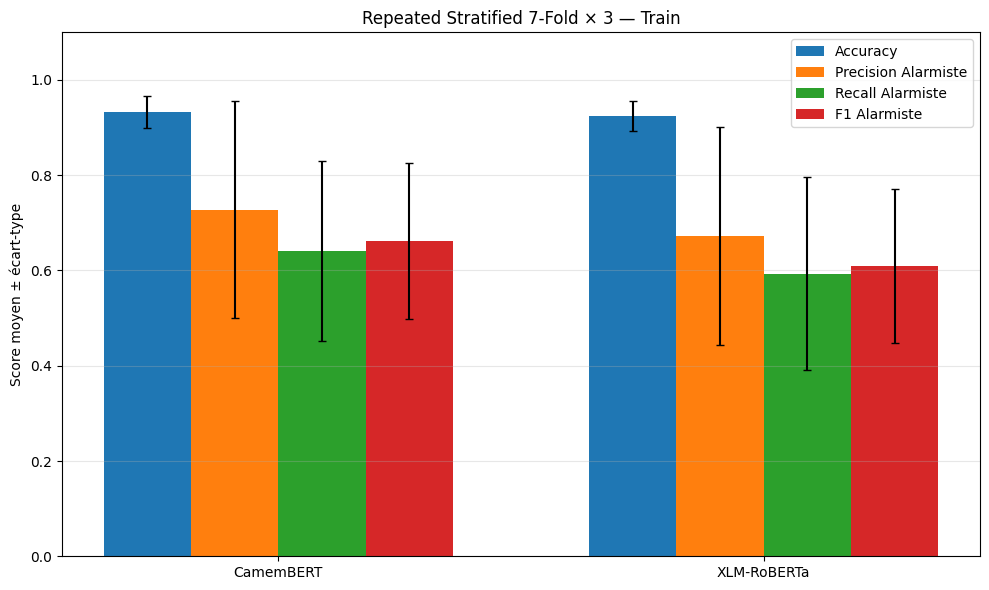

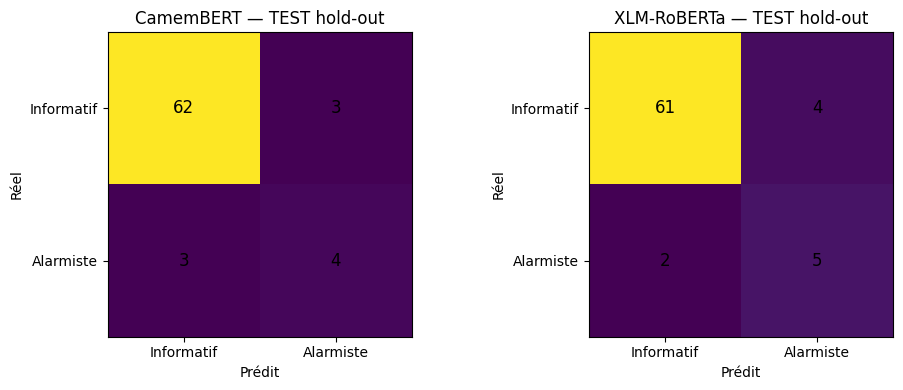


✅ Analyse terminée.
Les calculs ont été configurés pour le GPU NVIDIA/CUDA.
Parallélisme DataLoader : 2 workers.
GPU NVIDIA disponibles : 1.


In [ ]:
# ============================================================
# 6. COMPARAISON FINALE
# ============================================================

results_all = pd.concat(
    [results_camembert, results_xlmr],
    ignore_index=True
)

summary_all = (
    results_all.groupby("model")[
        [
            "accuracy",
            "precision_alarmiste",
            "recall_alarmiste",
            "f1_alarmiste",
            "f1_macro"
        ]
    ].agg(["mean", "std"])
)

print("=" * 70)
print(
    f"COMPARAISON — Repeated Stratified {N_SPLITS}-Fold × "
    f"{N_REPEATS} répétitions"
)
print("=" * 70)
print(summary_all.round(4))

# -------------------------------
# Résultats CV
# -------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

model_names = ["CamemBERT", "XLM-RoBERTa"]
x = np.arange(len(model_names))
width = 0.18

metrics_to_plot = [
    "accuracy",
    "precision_alarmiste",
    "recall_alarmiste",
    "f1_alarmiste"
]

for i, metric in enumerate(metrics_to_plot):
    means = [
        results_all.loc[
            results_all["model"] == model,
            metric
        ].mean()
        for model in model_names
    ]

    stds = [
        results_all.loc[
            results_all["model"] == model,
            metric
        ].std()
        for model in model_names
    ]

    ax.bar(
        x + i * width,
        means,
        width,
        yerr=stds,
        capsize=3,
        label=metric.replace("_", " ").title()
    )

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(model_names)
ax.set_ylim(0, 1.10)
ax.set_ylabel("Score moyen ± écart-type")
ax.set_title(
    f"Repeated Stratified {N_SPLITS}-Fold × {N_REPEATS} — Train"
)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "comparaison_camembert_xlmr_NVIDIA_repeated_cv.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# -------------------------------
# Matrices de confusion du TEST
# -------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name, cm in [
    (axes[0], "CamemBERT", confusion_camembert_test),
    (axes[1], "XLM-RoBERTa", confusion_xlmr_test)
]:
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{name} — TEST hold-out")
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Informatif", "Alarmiste"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Informatif", "Alarmiste"])

    for i in range(2):
        for j in range(2):
            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=12
            )

plt.tight_layout()
plt.savefig(
    "matrices_confusion_test_NVIDIA.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("\n✅ Analyse terminée.")
print("Les calculs ont été configurés pour le GPU NVIDIA/CUDA.")
print(f"Parallélisme DataLoader : {NUM_WORKERS} workers.")
print(f"GPU NVIDIA disponibles : {N_GPUS}.")

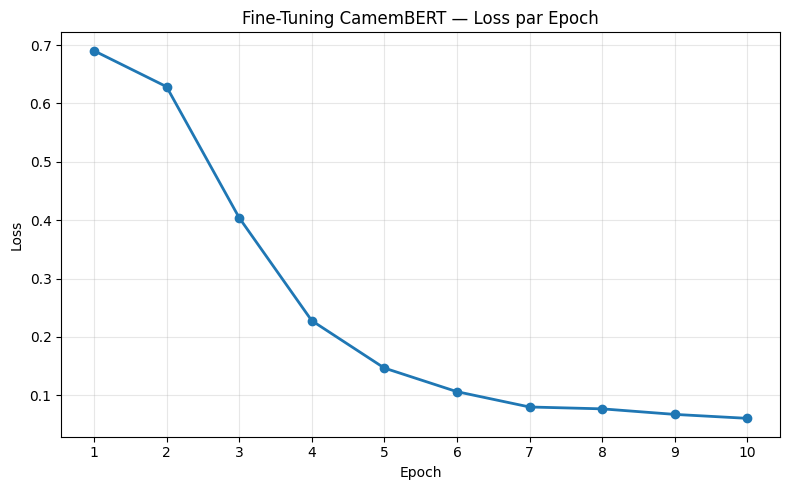

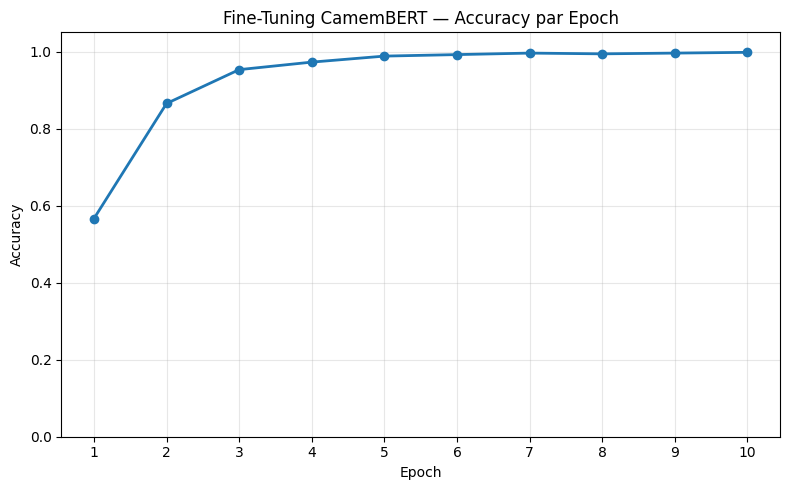

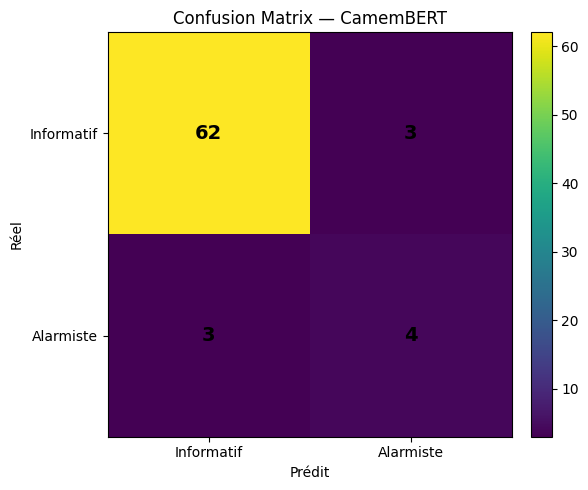

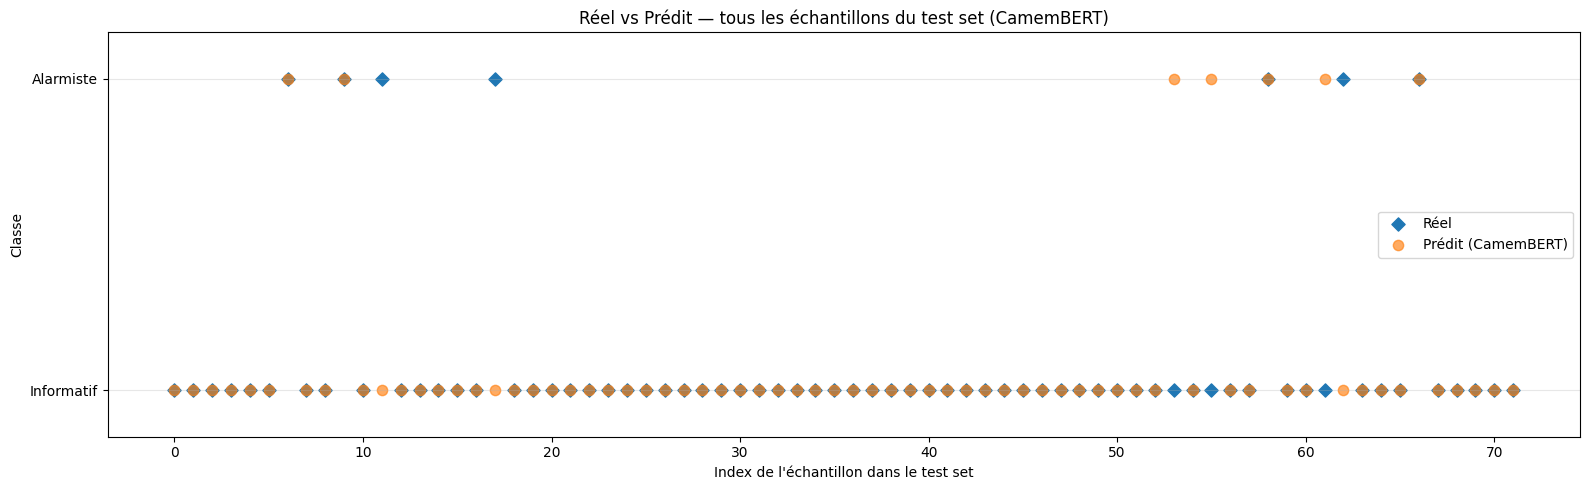


===== CamemBERT — DIAGNOSTICS =====
Échantillons testés : 72
Correctement classés : 66
Mal classés : 6
Accuracy test : 0.9167


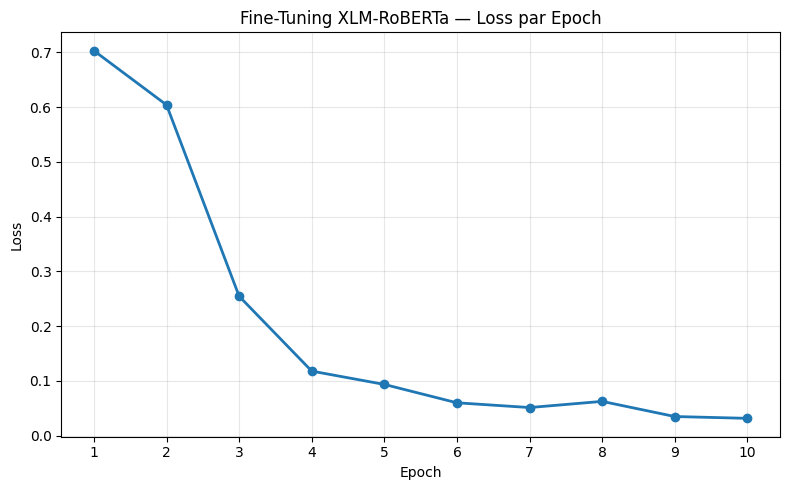

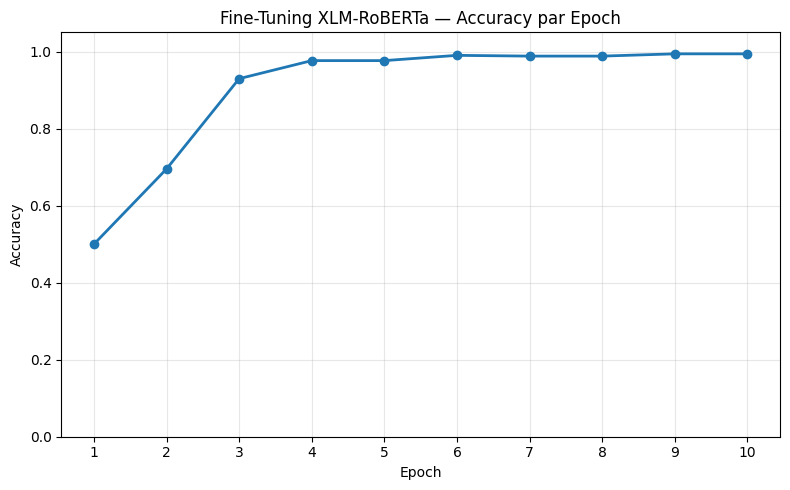

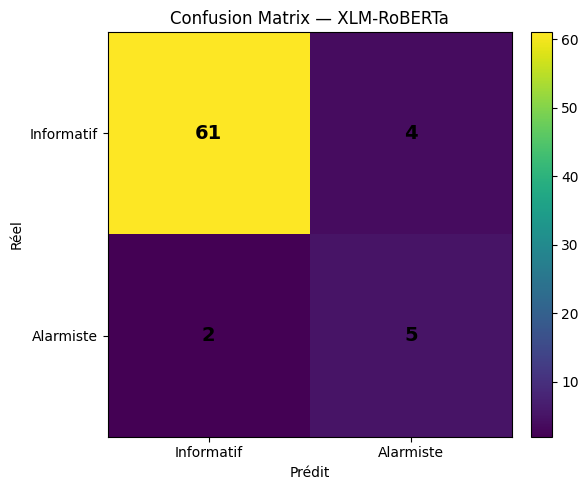

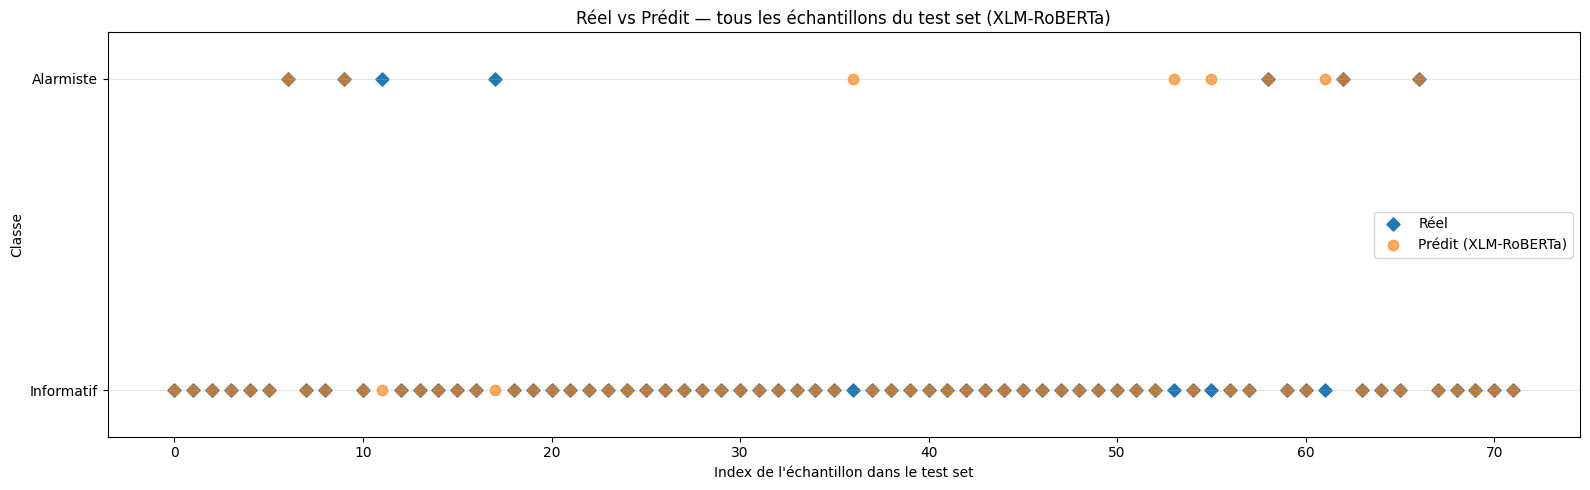


===== XLM-RoBERTa — DIAGNOSTICS =====
Échantillons testés : 72
Correctement classés : 66
Mal classés : 6
Accuracy test : 0.9167

✅ Les quatre analyses demandées ont été générées pour les deux Transformers.


In [ ]:
# ============================================================
# 6.1 ANALYSES GRAPHIQUES DÉTAILLÉES — TEST FINAL
# ============================================================
# Reproduction des quatre analyses de l'image fournie :
# 1) Loss par Epoch
# 2) Accuracy par Epoch
# 3) Matrice de confusion
# 4) Réel vs Prédit — tous les échantillons du test set
#
# Les courbes utilisent l'entraînement FINAL.
# La matrice et Réel/Prédit utilisent le TEST HOLD-OUT, non rééchantillonné.

def plot_transformer_diagnostics(model_label, history, predictions, save_prefix):
    y_true = np.asarray(predictions["y_true"])
    y_pred = np.asarray(predictions["y_pred"])
    epochs = history["epoch"]

    # 1. LOSS PAR EPOCH
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["loss"], marker="o", linewidth=2)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Fine-Tuning {model_label} — Loss par Epoch")
    plt.xticks(epochs)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{save_prefix}_loss_par_epoch.png", dpi=150, bbox_inches="tight")
    plt.show()

    # 2. ACCURACY PAR EPOCH
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["accuracy"], marker="o", linewidth=2)
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"Fine-Tuning {model_label} — Accuracy par Epoch")
    plt.xticks(epochs)
    plt.ylim(0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{save_prefix}_accuracy_par_epoch.png", dpi=150, bbox_inches="tight")
    plt.show()

    # 3. MATRICE DE CONFUSION
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    plt.figure(figsize=(6, 5))
    im = plt.imshow(cm, interpolation="nearest")
    plt.title(f"Confusion Matrix — {model_label}")
    plt.xlabel("Prédit")
    plt.ylabel("Réel")
    plt.xticks([0, 1], ["Informatif", "Alarmiste"])
    plt.yticks([0, 1], ["Informatif", "Alarmiste"])

    for i in range(2):
        for j in range(2):
            plt.text(j, i, str(cm[i, j]), ha="center", va="center",
                     fontsize=14, fontweight="bold")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig(f"{save_prefix}_matrice_confusion.png", dpi=150, bbox_inches="tight")
    plt.show()

    # 4. RÉEL VS PRÉDIT — TOUS LES ÉCHANTILLONS DU TEST
    sample_idx = np.arange(len(y_true))
    plt.figure(figsize=(16, 5))
    plt.scatter(sample_idx, y_true, marker="D", s=45, label="Réel")
    plt.scatter(sample_idx, y_pred, marker="o", s=55, alpha=0.65,
                label=f"Prédit ({model_label})")
    plt.yticks([0, 1], ["Informatif", "Alarmiste"])
    plt.ylim(-0.15, 1.15)
    plt.xlabel("Index de l'échantillon dans le test set")
    plt.ylabel("Classe")
    plt.title(f"Réel vs Prédit — tous les échantillons du test set ({model_label})")
    plt.grid(axis="y", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{save_prefix}_reel_vs_predit_test.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Export des prédictions.
    predictions_df = pd.DataFrame({
        "Index_test": sample_idx,
        "Label_reel": y_true,
        "Label_predit": y_pred,
        "Correct": y_true == y_pred
    })
    predictions_df["Label_reel_nom"] = predictions_df["Label_reel"].map({0: "Informatif", 1: "Alarmiste"})
    predictions_df["Label_predit_nom"] = predictions_df["Label_predit"].map({0: "Informatif", 1: "Alarmiste"})
    predictions_df.to_csv(f"{save_prefix}_predictions_test.csv", index=False, encoding="utf-8-sig")

    print(f"\n===== {model_label} — DIAGNOSTICS =====")
    print(f"Échantillons testés : {len(y_true)}")
    print(f"Correctement classés : {(y_true == y_pred).sum()}")
    print(f"Mal classés : {(y_true != y_pred).sum()}")
    print(f"Accuracy test : {accuracy_score(y_true, y_pred):.4f}")
    return predictions_df


diagnostics_camembert = plot_transformer_diagnostics(
    "CamemBERT", history_camembert, predictions_camembert, "CamemBERT_diagnostics"
)
diagnostics_xlmr = plot_transformer_diagnostics(
    "XLM-RoBERTa", history_xlmr, predictions_xlmr, "XLM-RoBERTa_diagnostics"
)

print("\n✅ Les quatre analyses demandées ont été générées pour les deux Transformers.")


In [ ]:
# ============================================================
# 7. EXPORT DES RESULTATS POUR LES ANALYSES COMPLEMENTAIRES
# ============================================================
# Cela n'affecte ni l'entraînement ni les pipelines, juste l'exportation des mal classés
# afin de les fusionner avec ceux des autres modèles si necessaire

import pandas as pd

# -------------------------------
# 7.1 Table des metriques finales
# -------------------------------
rows = []
for label, metrics in [("CamemBERT", metrics_camembert_test), ("XLM-RoBERTa", metrics_xlmr_test)]:
    rows.append({
        "Modele": label, "Categorie": "Informatif",
        "precision": metrics["precision_informatif"], "recall": metrics["recall_informatif"],
        "f1": metrics["f1_informatif"], "accuracy": metrics["accuracy"],
    })
    rows.append({
        "Modele": label, "Categorie": "Alarmiste",
        "precision": metrics["precision_alarmiste"], "recall": metrics["recall_alarmiste"],
        "f1": metrics["f1_alarmiste"], "accuracy": None,
    })
table1_transformers = pd.DataFrame(rows)
table1_transformers.to_csv("resultats_transformers_test.csv", index=False)
print("Exporte : resultats_transformers_test.csv")
print(table1_transformers)

# -------------------------------
# 7.2 Posts mal classes du TEST (pour le Tableau 2 de l'article)
# -------------------------------

misclassified_records = []

for label, model_name in [("CamemBERT", MODEL_NAME_CAMEMBERT), ("XLM-RoBERTa", MODEL_NAME_XLMR)]:
    output_dir = f"/content/{label.lower().replace('-', '_')}_mpox_final"
    tok = AutoTokenizer.from_pretrained(output_dir)
    mdl = AutoModelForSequenceClassification.from_pretrained(output_dir).to(DEVICE)
    mdl.eval()

    test_loader_inf = make_loader(X_test, y_test, tok, shuffle=False)
    y_true_inf, y_pred_inf = evaluate_model(mdl, test_loader_inf)

    for text, yt, yp in zip(X_test.tolist(), y_true_inf, y_pred_inf):
        if yt != yp:
            misclassified_records.append({
                "Modele": label,
                "Texte": text,
                "Label_vrai": "Alarmiste" if yt == 1 else "Informatif",
                "Label_predit": "Alarmiste" if yp == 1 else "Informatif",
            })

    del tok, mdl, test_loader_inf
    gc.collect()
    torch.cuda.empty_cache()

misclassified_transformers_df = pd.DataFrame(misclassified_records)
misclassified_transformers_df.to_csv("misclassified_transformers_test.csv", index=False)
print(f"\nExporte : misclassified_transformers_test.csv ({len(misclassified_transformers_df)} posts mal classes)")
misclassified_transformers_df


Exporte : resultats_transformers_test.csv
        Modele   Categorie  precision    recall        f1  accuracy
0    CamemBERT  Informatif   0.953846  0.953846  0.953846  0.916667
1    CamemBERT   Alarmiste   0.571429  0.571429  0.571429       NaN
2  XLM-RoBERTa  Informatif   0.968254  0.938462  0.953125  0.916667
3  XLM-RoBERTa   Alarmiste   0.555556  0.714286  0.625000       NaN


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Exporte : misclassified_transformers_test.csv (12 posts mal classes)


,Modele,Texte,Label_vrai,Label_predit
0,CamemBERT,la croixrouge du burundi a présenté son bilan ...,Alarmiste,Informatif
1,CamemBERT,les risques sanitaires comme le mpox et les mo...,Alarmiste,Informatif
2,CamemBERT,la représentante de lunicef au burundi a indiq...,Informatif,Alarmiste
3,CamemBERT,face aux rumeurs sur un cas présumé de mpox en...,Informatif,Alarmiste
4,CamemBERT,des quartiers de bujumbura sont privés deau de...,Informatif,Alarmiste
5,CamemBERT,le mpox pendant la grossesse présente de grave...,Alarmiste,Informatif
6,XLM-RoBERTa,la croixrouge du burundi a présenté son bilan ...,Alarmiste,Informatif
7,XLM-RoBERTa,les risques sanitaires comme le mpox et les mo...,Alarmiste,Informatif
8,XLM-RoBERTa,au septembre la république démocratique du con...,Informatif,Alarmiste
9,XLM-RoBERTa,la représentante de lunicef au burundi a indiq...,Informatif,Alarmiste


In [ ]:
display(misclassified_transformers_df)

,Modele,Texte,Label_vrai,Label_predit
0,CamemBERT,la croixrouge du burundi a présenté son bilan ...,Alarmiste,Informatif
1,CamemBERT,les risques sanitaires comme le mpox et les mo...,Alarmiste,Informatif
2,CamemBERT,la représentante de lunicef au burundi a indiq...,Informatif,Alarmiste
3,CamemBERT,face aux rumeurs sur un cas présumé de mpox en...,Informatif,Alarmiste
4,CamemBERT,des quartiers de bujumbura sont privés deau de...,Informatif,Alarmiste
5,CamemBERT,le mpox pendant la grossesse présente de grave...,Alarmiste,Informatif
6,XLM-RoBERTa,la croixrouge du burundi a présenté son bilan ...,Alarmiste,Informatif
7,XLM-RoBERTa,les risques sanitaires comme le mpox et les mo...,Alarmiste,Informatif
8,XLM-RoBERTa,au septembre la république démocratique du con...,Informatif,Alarmiste
9,XLM-RoBERTa,la représentante de lunicef au burundi a indiq...,Informatif,Alarmiste
